# A genus filtration of the entropy cone
## A short computational walkthrough

Takayuki Uchiba

This notebook explains the construction and four of the manuscript's main results.
Its small examples and plots use NumPy, SciPy and Matplotlib. All logarithms
below are base 2, so entropies are in bits. The normalized ratios do not depend
on the logarithm base.

The notebook is self-contained: the small teaching examples and representative
ray data are embedded here. The exact, exhaustive checks are available through
the repository's **make verify** command.

In [ ]:
# import
from collections import Counter
from fractions import Fraction
from itertools import combinations, permutations, product
from math import log2, prod
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

MASKS = tuple(range(1, 16))
def label(mask):
    return "".join(str(i + 1) for i in range(4) if mask & (1 << i))

def entropy_vector(atoms, probabilities=None):
    """Joint entropies of all nonempty subsets, in bitmask order."""
    atoms = [tuple(x) for x in atoms]
    if probabilities is None:
        probabilities = [Fraction(1, len(atoms))] * len(atoms)
    probabilities = [Fraction(p) for p in probabilities]
    assert len(atoms) == len(probabilities)
    assert all(p >= 0 for p in probabilities)
    assert sum(probabilities) == 1
    result = []
    for mask in MASKS:
        marginal = Counter()
        for atom, p in zip(atoms, probabilities):
            key = tuple(atom[i] for i in range(4) if mask & (1 << i))
            marginal[key] += p
        result.append(-sum(float(p) * log2(float(p))
                           for p in marginal.values() if p))
    return np.array(result)

J_ROW = np.array([-1,-1,1,0,1,1,-1,0,1,1,-1,-1,0,0,0])
def J(h):
    return float(J_ROW @ h)

def table(headers, rows):
    rows = [[str(x) for x in row] for row in rows]
    widths = [max(len(str(headers[j])), *(len(row[j]) for row in rows))
              for j in range(len(headers))]
    print(" | ".join(str(x).ljust(w) for x,w in zip(headers,widths)))
    for row in rows:
        print(" | ".join(x.ljust(w) for x,w in zip(row,widths)))

## 1. What is the random variable $X_i=UH_i$?

Choose a uniform group element $U\in G$. For a subgroup $H_i$, the value of
$X_i$ is the **left coset** $UH_i$: a set of group elements. It is not an
entropy value. Two elements give the same observation exactly when they
belong to the same coset.

For a set of observations $S$, put $H_S=\bigcap_{i\in S}H_i$. The joint
coset observation is uniform on $[G:H_S]$ possible values, hence

$$h_S=H(X_S)=\log_2[G:H_S].$$

Here $G=\mathbb F_2^2$, with a uniform element $(A,B)$. Take
$H_1=\ker A$, $H_2=\ker B$, $H_3=\ker(A+B)$ and $H_4=G$.
Their cosets are labeled by $A,B,A+B,0$, respectively.

In [2]:
G2 = list(product(range(2), repeat=2))
observe = lambda u: (u[0], u[1], (u[0] + u[1]) % 2, 0)
observations = [observe(u) for u in G2]
subgroups = [{u for u in G2 if observe(u)[i] == 0} for i in range(4)]

table(["uniform U", "X1", "X2", "X3", "X4"],
      [(str(u), *observe(u)) for u in G2])

direct = entropy_vector(observations)
intersection_orders = []
for mask in MASKS:
    chosen = [subgroups[i] for i in range(4) if mask & (1 << i)]
    intersection_orders.append(len(set.intersection(*chosen)))
indices = np.array([len(G2) // order for order in intersection_orders])
from_group = np.log2(indices)
assert np.allclose(direct, from_group, atol=1e-12)

print()
table(["S", "|intersection H_i|", "index", "entropy from probabilities"],
      [(label(mask), order, index, f"{entropy:.6f}")
       for mask,order,index,entropy in
       zip(MASKS, intersection_orders, indices, direct)])
print("\nThe probability calculation agrees with the subgroup-index formula.")

uniform U | X1 | X2 | X3 | X4
(0, 0)    | 0  | 0  | 0  | 0 
(0, 1)    | 0  | 1  | 1  | 0 
(1, 0)    | 1  | 0  | 1  | 0 
(1, 1)    | 1  | 1  | 0  | 0 

S    | |intersection H_i| | index | entropy from probabilities
1    | 2                  | 2     | 1.000000                  
2    | 2                  | 2     | 1.000000                  
12   | 1                  | 4     | 2.000000                  
3    | 2                  | 2     | 1.000000                  
13   | 1                  | 4     | 2.000000                  
23   | 1                  | 4     | 2.000000                  
123  | 1                  | 4     | 2.000000                  
4    | 4                  | 1     | -0.000000                 
14   | 2                  | 2     | 1.000000                  
24   | 2                  | 2     | 1.000000                  
124  | 1                  | 4     | 2.000000                  
34   | 2                  | 2     | 1.000000                  
134  | 1                  | 4 

## 2. Where does genus enter?

The entropy vector depends on the finite group and its subgroups.
Geometry restricts which groups are admitted: a group must act faithfully
on a smooth projective complex curve of genus between 2 and $g$.
The conical hull of all such vectors is $C_g(4)$.

Each finite stage is polyhedral. The closure of their nested union is the
almost-entropic cone, by group approximation and curve realization.
A general computable rate of convergence is not supplied.

The manuscript proves the strict chain

$$C_2(4)\subsetneq C_3(4)\subsetneq L_4\subsetneq C_4(4),$$

where $L_4$ is the Shannon cone cut by all six Ingleton inequalities.

Two useful distributions are uniform linear observations:
$A,B,C,A+B+C$ over $\mathbb F_2$, and $A,B,A+B,A-B$ over
$\mathbb F_3$. They have the uniform rank profiles $u_{3,4}$ and
$u_{2,4}$, after scaling by the entropy of one field element.
The manuscript supplies their genus-three and genus-four curve actions.

In [3]:
binary_atoms = [(a,b,c,(a+b+c) % 2)
                for a,b,c in product(range(2), repeat=3)]
ternary_atoms = [(a,b,(a+b) % 3,(a-b) % 3)
                 for a,b in product(range(3), repeat=2)]
u34 = entropy_vector(binary_atoms)
u24 = entropy_vector(ternary_atoms) / log2(3)

assert np.allclose(u34, [min(mask.bit_count(),3) for mask in MASKS])
assert np.allclose(u24, [min(mask.bit_count(),2) for mask in MASKS])
table(["S", "binary profile u_(3,4)", "ternary profile u_(2,4)"],
      [(label(mask), int(round(x)), int(round(y)))
       for mask,x,y in zip(MASKS,u34,u24)])

S    | binary profile u_(3,4) | ternary profile u_(2,4)
1    | 1                      | 1                      
2    | 1                      | 1                      
12   | 2                      | 2                      
3    | 1                      | 1                      
13   | 2                      | 2                      
23   | 2                      | 2                      
123  | 3                      | 2                      
4    | 1                      | 1                      
14   | 2                      | 2                      
24   | 2                      | 2                      
124  | 3                      | 2                      
34   | 2                      | 2                      
134  | 3                      | 2                      
234  | 3                      | 2                      
1234 | 3                      | 2                      


## 3. The genus-two cone: 18 symmetry orbits and 127 rays

The main finite calculation gives a 15-dimensional cone with 127 extreme
rays in 18 orbits under relabeling the four variables. Each integer vector
$d$ below represents the entropy vector $\log_2 d$, in bitmask order
$1,2,12,3,13,23,123,4,14,24,124,34,134,234,1234$.

The next cell expands the 18 stored representatives under the 24
permutations. This checks the orbit arithmetic. Extremality, membership
of every admissible genus-two group vector, and the recorded subgroup
witnesses are checked by the exact verification suite. The curve actions
and classification of admissible groups are established in the manuscript
using the cited literature.

orbit | number of rays | singleton indices | joint index
1     | 4              | [1, 1, 1, 2]      | 2          
2     | 6              | [1, 1, 2, 2]      | 2          
3     | 4              | [1, 2, 2, 2]      | 2          
4     | 4              | [1, 2, 2, 2]      | 4          
5     | 1              | [2, 2, 2, 2]      | 2          
6     | 6              | [2, 2, 2, 2]      | 4          
7     | 4              | [2, 2, 2, 4]      | 4          
8     | 6              | [2, 2, 3, 3]      | 12         
9     | 12             | [2, 2, 3, 6]      | 12         
10    | 6              | [2, 2, 4, 4]      | 8          
11    | 12             | [2, 3, 4, 4]      | 24         
12    | 12             | [2, 4, 4, 6]      | 24         
13    | 12             | [2, 4, 6, 6]      | 24         
14    | 12             | [2, 6, 8, 8]      | 48         
15    | 12             | [3, 3, 4, 8]      | 24         
16    | 4              | [4, 4, 4, 6]      | 24         
17    | 6              | [6, 6,

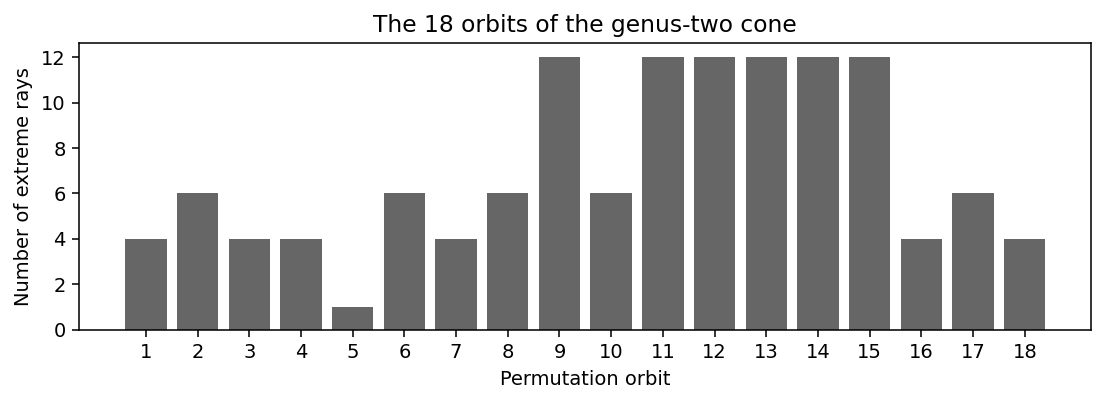

In [4]:
REPRESENTATIVES = [{"indices":[1,1,1,1,1,1,1,2,2,2,2,2,2,2,2],"orbit_size":4},{"indices":[1,1,1,2,2,2,2,2,2,2,2,2,2,2,2],"orbit_size":6},{"indices":[1,2,2,2,2,2,2,2,2,2,2,2,2,2,2],"orbit_size":4},{"indices":[1,2,2,2,2,4,4,2,2,4,4,4,4,4,4],"orbit_size":4},{"indices":[2,2,2,2,2,2,2,2,2,2,2,2,2,2,2],"orbit_size":1},{"indices":[2,2,2,2,4,4,4,2,4,4,4,4,4,4,4],"orbit_size":6},{"indices":[2,2,4,2,4,4,4,4,4,4,4,4,4,4,4],"orbit_size":4},{"indices":[2,2,4,3,6,6,12,3,6,6,12,6,12,12,12],"orbit_size":6},{"indices":[2,2,4,3,6,6,12,6,12,12,12,12,12,12,12],"orbit_size":12},{"indices":[2,2,4,4,8,8,8,4,8,8,8,8,8,8,8],"orbit_size":6},{"indices":[2,3,6,4,8,12,24,4,8,12,24,12,24,24,24],"orbit_size":12},{"indices":[2,4,8,4,8,12,24,6,12,24,24,24,24,24,24],"orbit_size":12},{"indices":[2,4,8,6,12,24,24,6,12,24,24,24,24,24,24],"orbit_size":12},{"indices":[2,6,12,8,16,48,48,8,16,48,48,48,48,48,48],"orbit_size":12},{"indices":[3,3,6,4,12,12,24,8,24,24,24,24,24,24,24],"orbit_size":12},{"indices":[4,4,12,4,12,12,24,6,24,24,24,24,24,24,24],"orbit_size":4},{"indices":[6,6,24,8,48,48,48,8,48,48,48,48,48,48,48],"orbit_size":6},{"indices":[6,8,48,8,48,48,48,8,48,48,48,48,48,48,48],"orbit_size":4}]

def permute_profile(vector, p):
    return tuple(vector[sum(1 << p[i] for i in range(4) if mask & (1 << i)) - 1]
                 for mask in MASKS)

orbits = [{permute_profile(row["indices"], p)
           for p in permutations(range(4))}
          for row in REPRESENTATIVES]
assert all(len(orbit) == row["orbit_size"]
           for orbit,row in zip(orbits,REPRESENTATIVES))
all_rays = set().union(*orbits)
assert len(REPRESENTATIVES) == 18
assert len(all_rays) == sum(map(len,orbits)) == 127

table(["orbit", "number of rays", "singleton indices", "joint index"],
      [(i+1, len(orbit), [row["indices"][mask-1] for mask in (1,2,4,8)],
        row["indices"][-1])
       for i,(orbit,row) in enumerate(zip(orbits,REPRESENTATIVES))])
print("\nTotal:", len(all_rays), "rays.")

plt.figure(figsize=(8,3))
plt.bar(range(1,19), [len(orbit) for orbit in orbits], color="0.4")
plt.xticks(range(1,19))
plt.xlabel("Permutation orbit")
plt.ylabel("Number of extreme rays")
plt.title("The 18 orbits of the genus-two cone")
plt.tight_layout()
plt.show()

### A three-dimensional view of the symmetric slice

For a symmetric entropy vector, all subsets of the same size have equal
entropy. Write $A=\sum_i h_i$, $B=\sum_{i<j}h_{ij}$,
$D=\sum_{i<j<k}h_{ijk}$ and $T=h_{1234}$. The slice $T=1$ of
the symmetric part of $C_2(4)$ has eight vertices and eight facets.

The picture shows this symmetric slice. The full cone has 15 coordinates.
The coefficients of the eight vertices are polynomials in $r=\log_2 3$,
recorded in ascending powers. We evaluate them only for plotting.

One exact genus-two supporting inequality is

$$F_1(h)=(1+r)A+(1-r)B+(r-2)D+(2-r)T\geq0.$$

On $u_{3,4}/3$, it has value $(r-2)/3<0$. Together with the curve action
from the preceding section, this exhibits $C_2(4)\subsetneq C_3(4)$.

F1(u_(3,4)/3) = -0.138345833 < 0


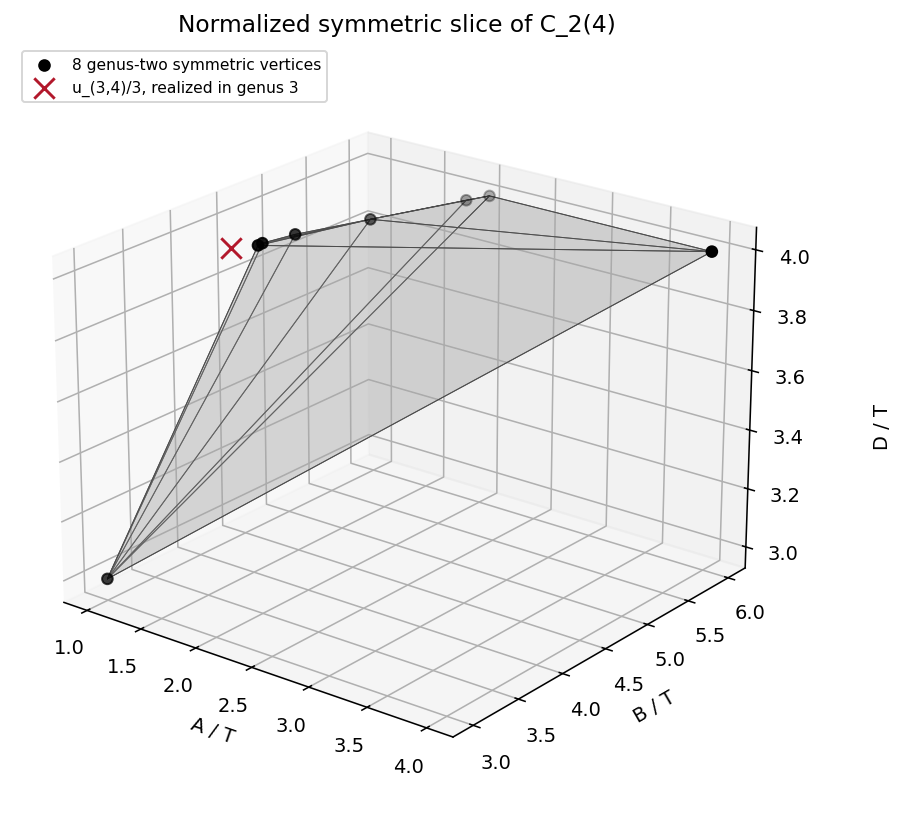

In [5]:
VERTEX_POLYNOMIALS = [[[4],[6],[4],[1]],[[1],[3],[3],[1]],[[3],[9],[8],[2]],[[2,2],[7,5],[8,4],[2,1]],[[10,1],[24,6],[16,4],[4,1]],[[8,2],[23,6],[16,4],[4,1]],[[8,1],[22,4],[16,4],[4,1]],[[5,1],[13,4],[12,4],[3,1]]]
FACET_POLYNOMIALS = [[[1,1,0],[1,-1,0],[-2,1,0],[2,-1,0]],[[8,-1,0],[-4,1,0],[2,-1,0],[-2,1,0]],[[4,9,2],[0,-4,-1],[-4,2,1],[8,-3,-2]],[[4,1,0],[-8,2,1],[18,-6,-3],[-34,11,6]],[[5,-1,-1],[-4,1,1],[2,0,-1],[1,-2,1]],[[0,0,0],[-2,-1,0],[6,3,0],[-12,-6,0]],[[-5,-1,0],[6,2,0],[-3,-3,0],[-4,4,0]],[[0],[0],[-1],[4]]]

r = log2(3)
evaluate = lambda coefficients: sum(coefficient * r**degree
                                   for degree,coefficient in enumerate(coefficients))
symmetric_rays = np.array([[evaluate(p) for p in row]
                           for row in VERTEX_POLYNOMIALS])
vertices3d = symmetric_rays[:,:3] / symmetric_rays[:,3,None]
facet_matrix = np.array([[evaluate(p) for p in row]
                         for row in FACET_POLYNOMIALS])
assert len(vertices3d) == len(facet_matrix) == 8
assert np.min(facet_matrix @ np.column_stack([vertices3d,np.ones(8)]).T) > -1e-11

normalized_u34 = np.array([4/3,4,4,1])
f1 = np.array([1+r,1-r,r-2,2-r])
assert np.isclose(f1 @ normalized_u34, (r-2)/3)
assert f1 @ normalized_u34 < 0
print("F1(u_(3,4)/3) =", f"{f1 @ normalized_u34:.9f}", "< 0")

hull = ConvexHull(vertices3d)
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111,projection="3d")
surface = Poly3DCollection([vertices3d[s] for s in hull.simplices],
                          facecolor="0.65",edgecolor="0.3",linewidth=0.5,alpha=0.25)
ax.add_collection3d(surface)
ax.scatter(*vertices3d.T,color="black",s=30,label="8 genus-two symmetric vertices")
ax.scatter(*normalized_u34[:3],marker="x",color="#b2182b",s=110,
           label="u_(3,4)/3, realized in genus 3")
ax.set_xlabel("A / T"); ax.set_ylabel("B / T")
ax.text2D(1.12, 0.50, "D / T", transform=ax.transAxes, rotation=90, va="center")
ax.view_init(elev=22,azim=-52)
ax.set_title("Normalized symmetric slice of C_2(4)")
ax.legend(loc="upper left",fontsize=8)
plt.tight_layout()
plt.show()

## 4. A concrete Ingleton violation in $S_5$

Use the sign convention

$$J(h)=I(1;2\mid3)+I(1;2\mid4)+I(3;4)-I(1;2).$$

Ingleton asks for $J\geq0$. The following four subgroups of $S_5$ give
a negative value:

$$
\begin{aligned}
H_1&=\langle(345),(12)(45)\rangle, &
H_2&=\langle(2345),(12)(34)\rangle,\\
H_3&=\langle(23),(12)(35)\rangle, &
H_4&=\langle(25),(12)(45)\rangle.
\end{aligned}
$$

We construct these groups from their generators, then calculate all
intersection indices. Composition acts from right to left.

In [6]:
def permutation(*cycles):
    p = list(range(5))
    for cycle in cycles:
        for a,b in zip(cycle,cycle[1:] + cycle[:1]):
            p[a-1] = b-1
    return tuple(p)

def compose(p,q):
    return tuple(p[q[i]] for i in range(5))

def subgroup_generated_by(generators):
    identity = tuple(range(5))
    seen = {identity}
    todo = [identity]
    while todo:
        x = todo.pop()
        for generator in generators:
            y = compose(x,generator)
            if y not in seen:
                seen.add(y); todo.append(y)
    return seen

generators = [
    [permutation((3,4,5)), permutation((1,2),(4,5))],
    [permutation((2,3,4,5)), permutation((1,2),(3,4))],
    [permutation((2,3)), permutation((1,2),(3,5))],
    [permutation((2,5)), permutation((1,2),(4,5))],
]
H = [subgroup_generated_by(gens) for gens in generators]
assert list(map(len,H)) == [6,20,8,8]
G5 = list(permutations(range(5)))
orders = [len(set.intersection(*[H[i] for i in range(4) if mask & (1 << i)]))
          for mask in MASKS]
d5 = np.array([120 // order for order in orders])
assert d5.tolist() == [20,6,60,15,60,30,120,15,60,30,120,120,120,120,120]
h5 = np.log2(d5)
table(["S", "|H_S|", "[S5:H_S]", "H(X_S), bits"],
      [(label(mask), order, d, f"{h:.6f}")
       for mask,order,d,h in zip(MASKS,orders,d5,h5)])

S    | |H_S| | [S5:H_S] | H(X_S), bits
1    | 6     | 20       | 4.321928    
2    | 20    | 6        | 2.584963    
12   | 2     | 60       | 5.906891    
3    | 8     | 15       | 3.906891    
13   | 2     | 60       | 5.906891    
23   | 4     | 30       | 4.906891    
123  | 1     | 120      | 6.906891    
4    | 8     | 15       | 3.906891    
14   | 2     | 60       | 5.906891    
24   | 4     | 30       | 4.906891    
124  | 1     | 120      | 6.906891    
34   | 1     | 120      | 6.906891    
134  | 1     | 120      | 6.906891    
234  | 1     | 120      | 6.906891    
1234 | 1     | 120      | 6.906891    


We can also create the actual coset-valued observations of a uniform
permutation. A coset is labeled by its lexicographically smallest element.
This is a label for the entire set $uH_i$.

In [7]:
def coset_labels(group,subgroup):
    labels = {}
    for u in group:
        if u in labels:
            continue
        coset = {compose(u,v) for v in subgroup}
        representative = min(coset)
        labels.update({v:representative for v in coset})
    assert len(labels) == len(group)
    return labels

cosets = [coset_labels(G5,subgroup) for subgroup in H]
coset_atoms = [tuple(labels[u] for labels in cosets) for u in G5]
direct_h5 = entropy_vector(coset_atoms)
assert np.allclose(direct_h5,h5,atol=1e-12)

orders_by_mask = dict(zip(MASKS,orders))
ell = prod(orders_by_mask[m] for m in (1,2,12,7,11))
v = prod(orders_by_mask[m] for m in (3,5,9,6,10))
ratio = Fraction(ell,v)
assert ratio == Fraction(15,16)
assert np.isclose(J(h5), log2(float(ratio)))
c = log2(16/15) / log2(120)
assert J(h5) < 0
assert abs(J(h5) + c*h5[-1]) < 1e-12

print("Subgroup orders:", list(map(len,H)))
print("Exact Ingleton ratio ell / v:", ratio)
print("J(h) =", f"{J(h5):.9f}", "bits")
print("Normalized violation -J(h)/T =", f"{-J(h5)/h5[-1]:.9f}")
print("Sharp genus-four inequality J(h) + c*T =", f"{J(h5)+c*h5[-1]:.3e}")

Subgroup orders: [6, 20, 8, 8]
Exact Ingleton ratio ell / v: 15/16
J(h) = -0.093109404 bits
Normalized violation -J(h)/T = 0.013480654
Sharp genus-four inequality J(h) + c*T = -7.355e-16


The manuscript uses the faithful $S_5$ action on Bring's genus-four curve
to put this vector in $C_4(4)$. Curve classifications and group checks
establish that genus two and three satisfy Ingleton, and that

$$J(h)+cT\geq0\quad(h\in C_4(4)),\qquad
c=\frac{\log(16/15)}{\log120}.$$

This example attains equality, so $c$ is sharp.

For a Shannon vector with $T=1$, the manuscript's repair formula computes
its distance to the normalized Ingleton cone $P_L$. For this example the
distance is $c/10$; its distance to $P_4$ is zero because it already belongs
to $P_4$.

In [8]:
normalized_h5 = h5 / h5[-1]
repaired = normalized_h5 - J(normalized_h5) * J_ROW / 10
distance_to_ingleton_slice = np.max(np.abs(repaired-normalized_h5))
assert np.isclose(J(repaired),0,atol=1e-12)
assert np.isclose(distance_to_ingleton_slice,c/10)
print("Distance of this point to P_L:", f"{distance_to_ingleton_slice:.9f}")
print("Distance of this point to P_4: 0")

Distance of this point to P_L: 0.001348065
Distance of this point to P_4: 0


## 5. From an Ingleton score to a genus-approximation error

Put $P_g=C_g(4)\cap\{T=1\}$, $P=\overline{\Gamma_4^*}\cap\{T=1\}$,
and $E_g=d_H^\infty(P,P_g)$. If $I^*=\min_{h\in P}J(h)$, the manuscript proves

$$\frac{-I^*-c}{10}\leq E_4\leq\frac{-I^*}{10}.$$

The unknown optimal score therefore determines an interval of width
$c/10$ for $E_4$.

For an explicit lower endpoint, the next cell uses the 40 rational atoms
in Matúš–Csirmaz, *Entropy region and convolution*, Example 2.
Each of the eight rows has the five column probabilities shown below.
We relabel the original variables to match our distinguished pair.

In [9]:
ATOM_TABLE = [
    ["0000","0210","0011","0010","0001"],
    ["0101","0321","0120","0121","0100"],
    ["1010","1100","1002","1000","1012"],
    ["1212","1332","1230","1232","1210"],
    ["2121","2001","2103","2101","2123"],
    ["2323","2233","2331","2333","2321"],
    ["3232","3012","3213","3212","3233"],
    ["3333","3123","3322","3323","3332"],
]
column_probabilities = [Fraction(n,100000) for n in (9524,2494,160,161,161)]
atoms40, probabilities40 = [], []
for row in ATOM_TABLE:
    for word,p in zip(row,column_probabilities):
        original = tuple(map(int,word))
        atoms40.append((original[2],original[3],original[0],original[1]))
        probabilities40.append(p)
assert len(set(atoms40)) == 40 and sum(probabilities40) == 1
f = entropy_vector(atoms40, probabilities40)

raw_score = J(f)/f[-1]
denominator = f[7-1] + f[11-1] + f[12-1] - 2*f[15-1]
sigma = -J(f)/denominator
assert denominator > 0
assert np.isclose(raw_score,-0.0782772346325,atol=1e-11)
assert 0.0924339 < sigma < 0.0924340

table(["quantity", "value"],
      [("Score of the original 40-atom distribution", f"{raw_score:.12f}"),
       ("Improved limiting violation score sigma", f"{sigma:.12f}"),
       ("Genus-four coefficient c", f"{c:.12f}")])

quantity                                   | value          
Score of the original 40-atom distribution | -0.078277234633
Improved limiting violation score sigma    | 0.092433957788 
Genus-four coefficient c                   | 0.013480654298 


The original distribution has normalized score about $-0.0782772$.
The improved quantity

$$\sigma=\frac{-J(f)}{f_{123}+f_{124}+f_{34}-2f_{1234}}
       =0.092433957788\ldots$$

is obtained as a limiting normalized violation score through the published
tightening/convolution construction. It is a different quantity from
$-J(f)/T(f)$.

The manuscript's rational interval calculation certifies this value.
Combining it with the published bound $I^*\geq-3/19$ gives

$$\frac{\sigma-c}{10}\leq E_4\leq\frac3{190},
\qquad E_3\geq\frac{\sigma}{10}.$$

The following plot displays these proved bounds. It does not compute the
exact Hausdorff errors or the whole almost-entropic cone.

error | certified lower endpoint | certified upper endpoint
E4    | 0.007895330349           | 0.015789473684          
E3    | 0.009243395779           | not determined here     


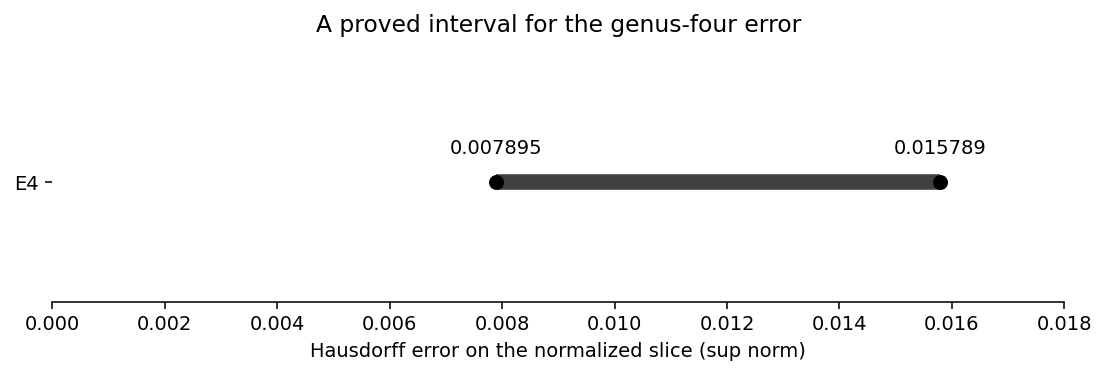

In [10]:
lower4, upper4 = (sigma-c)/10, 3/190
lower3 = sigma/10
assert np.isclose(lower4,0.007895330349,atol=1e-12)
assert np.isclose(lower3,0.009243395778,atol=1e-12)

table(["error", "certified lower endpoint", "certified upper endpoint"],
      [("E4", f"{lower4:.12f}", f"{upper4:.12f}"),
       ("E3", f"{lower3:.12f}", "not determined here")])

fig,ax = plt.subplots(figsize=(8,2.8))
ax.plot([lower4,upper4],[0,0],color="0.25",linewidth=8,solid_capstyle="butt")
ax.scatter([lower4,upper4],[0,0],color="black",s=45,zorder=3)
ax.annotate(f"{lower4:.6f}",(lower4,0),xytext=(0,15),
            textcoords="offset points",ha="center")
ax.annotate(f"{upper4:.6f}",(upper4,0),xytext=(0,15),
            textcoords="offset points",ha="center")
ax.set_xlim(0,0.018)
ax.set_ylim(-0.6,0.7)
ax.set_yticks([0],["E4"])
ax.set_xlabel("Hausdorff error on the normalized slice (sup norm)")
ax.set_title("A proved interval for the genus-four error")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
plt.tight_layout()
plt.show()

## Exact verification and sources

The notebook's displayed entropy values and plots use floating point.
The repository's **make verify** command checks the genus-two enumeration,
membership and exposure certificates, the Bolza witnesses, the genus-three
obstruction, the two larger-group Ingleton searches, repair identities and
rational score intervals using the methods described in each verifier.

The curve-action classification and the published exclusion of
Ingleton-violating groups of order less than 120 remain external inputs.
The explicit $3/19$ score bound used above is also a published theorem.

The 18 ray representatives and symmetric vertices come from the manuscript's
certified genus-two data. The $S_5$ example is the explicit first witness in
our integer subgroup search. The rational 40-atom distribution is from:

- Matúš and Csirmaz, [Entropy region and convolution](https://arxiv.org/abs/1310.5957).
- For the group example and limiting-score interpretation, see Boston and Nan,
  [Violations of the Ingleton inequality and revising the four-atom conjecture](https://www.kybernetika.cz/content/2020/5/916/paper.pdf).

For details and bibliographic provenance, see the manuscript and the source
notes under **revision/**.